**Tutorial Code by Amirhossein Ahrari YouTube:** https://www.youtube.com/@amirhosseinahrarigee

**Tutorial Video: PySTAC Tutorial-12: Sentinel-2 Crop Type Mapping using Phenological Pattern and Time Series Analysis**

This code is part of a tutorial series on python eo programming techniques
presented on the Amirhossein Ahrari YouTube channel. You are free to use and modify
this code for academic and non-academic purposes. Don't forget to subscribe to
the Amirhossein Ahrari channel and follow the videos to support the instructor.

In [1]:
!pip install -q pystac-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 7.6 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [48.435381, 32.172246, 48.471934, 32.204948]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2025'
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [9]:
len(items)

87

In [12]:
items[0].properties['proj:code']

'EPSG:32639'

In [14]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [15]:
!pip install -q stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.6 MB/s eta 0:00:00


In [16]:
import stackstac

In [17]:
stack_items = stackstac.stack(
    items,
    assets = ['red','nir', 'scl'],
    bounds_latlon = roi,
    epsg = 32639,
    resolution = 10
)

In [23]:
ds = (
    stack_items.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [25]:
mask = ds.scl.isin([3,8,9,10]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [26]:
red = ds_mask['red']
nir = ds_mask['nir']
ndvi = (nir - red) / (nir + red)

In [28]:
ndvi_monthly = ndvi.resample(time = 'M').mean('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [30]:
from dask.diagnostics import ProgressBar

In [33]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [34]:
with ProgressBar():
  ndvi_monthly = ndvi_monthly.compute()

[########################################] | 100% Completed | 45.50 s


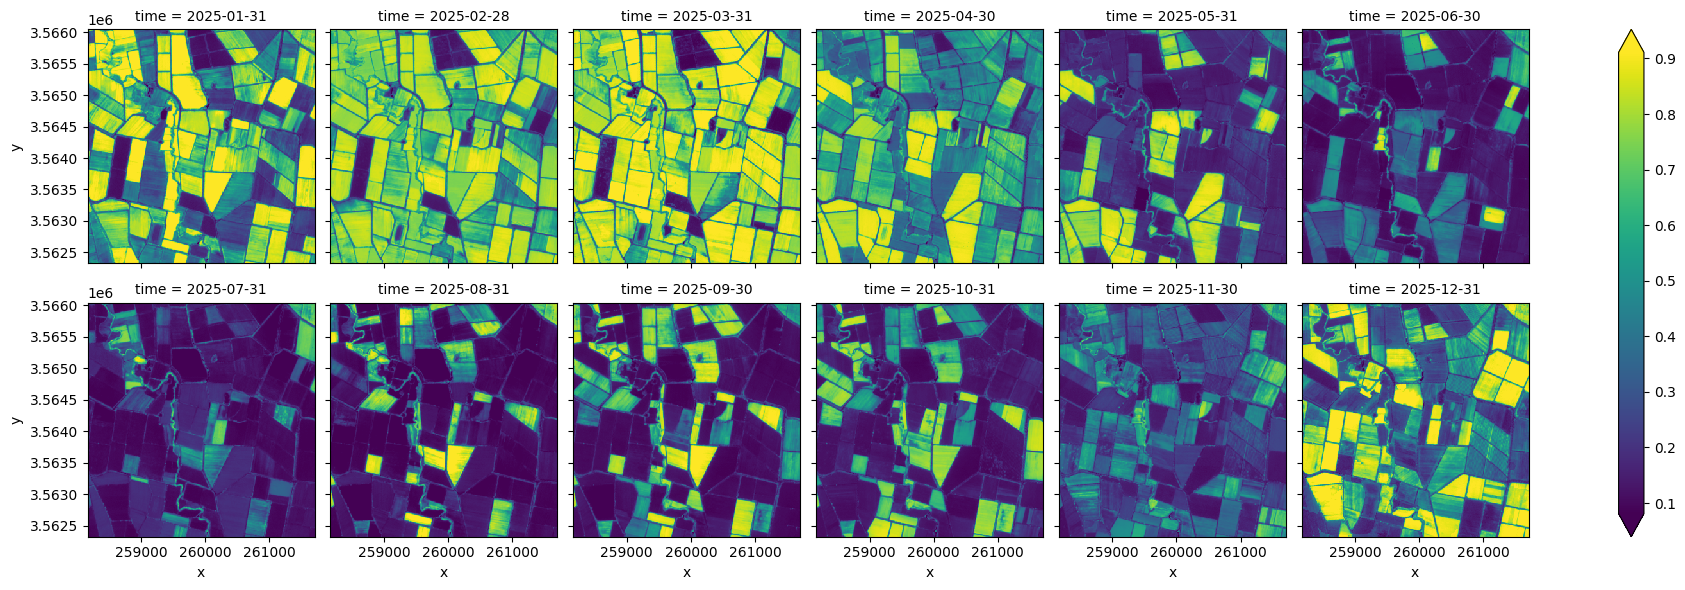

In [36]:
ndvi_monthly.plot(robust = True, col = 'time', col_wrap = 6)

In [37]:
from scipy.signal import savgol_filter

In [38]:
ndvi_monthly_vals = ndvi_monthly.values

In [41]:
ndvi_monthly

<xarray.DataArray (time: 12, y: 372, x: 354)> Size: 13MB
array([[[0.73122674, 0.69016058, 0.66883975, ..., 0.7526188 ,
         0.74986412, 0.7211006 ],
        [0.82194808, 0.81506281, 0.80790655, ..., 0.78121814,
         0.76227165, 0.75205509],
        [0.47719492, 0.47892549, 0.47935464, ..., 0.70549116,
         0.69897121, 0.74613817],
        ...,
        [0.51532652, 0.54026382, 0.45167687, ..., 0.5341177 ,
         0.53940622, 0.548996  ],
        [0.46697699, 0.58607731, 0.49595365, ..., 0.53894632,
         0.55263614, 0.55001552],
        [0.46183708, 0.64369957, 0.60854475, ..., 0.54735839,
         0.56357514, 0.5463016 ]],

       [[0.6706153 , 0.63094074, 0.59882802, ..., 0.63484982,
         0.6241324 , 0.61597765],
        [0.76407192, 0.75227312, 0.7361832 , ..., 0.66635276,
         0.64084781, 0.63657152],
        [0.57012836, 0.56778339, 0.55127323, ..., 0.60418962,
         0.59397429, 0.63549197],
...
        [0.12149829, 0.11691824, 0.11329025, ..., 0.46135309,
         0.44515144, 0.46427245],
        [0.12114507, 0.11930829, 0.11386196, ..., 0.45381755,
         0.44933824, 0.46638465],
        [0.12768247, 0.11842882, 0.11992103, ..., 0.45830332,
         0.45962163, 0.47028711]],

       [[0.24173206, 0.24975616, 0.26286054, ..., 0.76301073,
         0.75842779, 0.73531999],
        [0.26891589, 0.27113451, 0.2672208 , ..., 0.78579859,
         0.78143347, 0.76497482],
        [0.24970577, 0.24762901, 0.26121769, ..., 0.73583351,
         0.74104129, 0.77017886],
        ...,
        [0.15866455, 0.16195727, 0.16478555, ..., 0.89896338,
         0.89243955, 0.88962964],
        [0.15545824, 0.17852349, 0.15835141, ..., 0.89325198,
         0.89781108, 0.89966706],
        [0.1752322 , 0.18160136, 0.15159944, ..., 0.88990657,
         0.89443468, 0.89706583]]])
Coordinates:
  * time     (time) datetime64[ns] 96B 2025-01-31 2025-02-28 ... 2025-12-31
  * y        (y) float64 3kB 3.566e+06 3.566e+06 ... 3.562e+06 3.562e+06
  * x        (x) float64 3kB 2.582e+05 2.582e+05 ... 2.617e+05 2.617e+05

In [40]:
ndvi_monthly_vals.shape

(12, 372, 354)

In [42]:
help(savgol_filter)

Help on function savgol_filter in module scipy.signal._savitzky_golay:

savgol_filter(
    x,
    window_length,
    polyorder,
    deriv=0,
    delta=1.0,
    axis=-1,
    mode='interp',
    cval=0.0
)
    Apply a Savitzky-Golay filter to an array.

    This is a 1-D filter. If `x`  has dimension greater than 1, `axis`
    determines the axis along which the filter is applied.

    Parameters
    ----------
    x : array_like
        The data to be filtered. If `x` is not a single or double precision
        floating point array, it will be converted to type ``numpy.float64``
        before filtering.
    window_length : int
        The length of the filter window (i.e., the number of coefficients).
        If `mode` is 'interp', `window_length` must be less than or equal
        to the size of `x`.
    polyorder : int
        The order of the polynomial used to fit the samples.
        `polyorder` must be less than `window_length`.
    deriv : int, optional
        The order of the d

In [43]:
ndvi_filter = savgol_filter(
    ndvi_monthly_vals,
    window_length = 5,
    polyorder = 2,
    axis =  0
)

In [45]:
import xarray as xr

In [46]:
ndvi_smooth = xr.DataArray(
    ndvi_filter,
    dims = ndvi_monthly.dims,
    coords =ndvi_monthly.coords
)

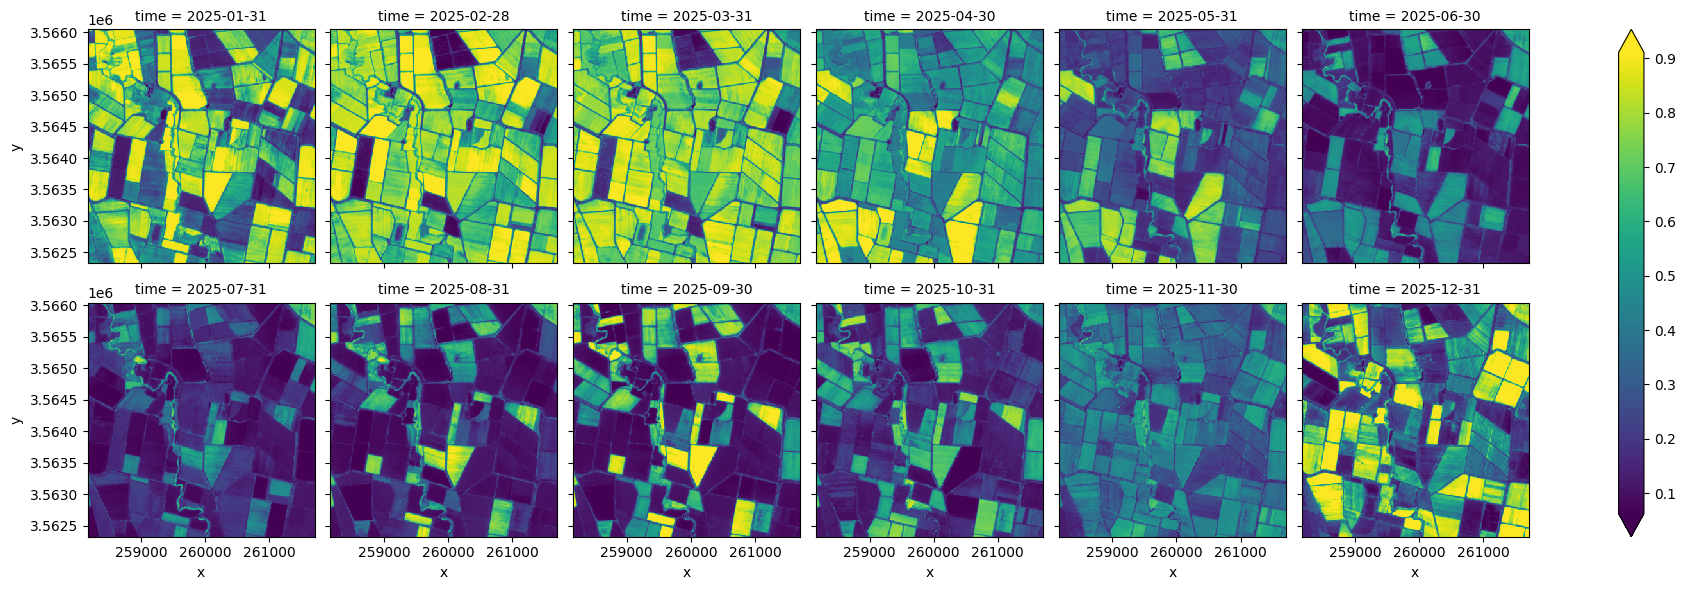

In [48]:
ndvi_smooth.plot(robust = True, col = 'time', col_wrap = 6)

In [49]:
!pip install -q tslearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 12.1 MB/s eta 0:00:00


In [50]:
from tslearn.clustering import TimeSeriesKMeans

In [53]:
ndvi_stack = ndvi_smooth.stack(pixel = ['y','x']).transpose('pixel', 'time')

In [54]:
valid = ndvi_stack.notnull().all('time')

In [56]:
model = TimeSeriesKMeans(
    n_clusters = 4,
    random_state =42,
    metric = 'euclidean',
    max_iter =10
)

In [57]:
labels = model.fit_predict(ndvi_stack[valid].values)

In [62]:
classified = xr.DataArray(
    labels,
    dims = 'pixel',
    coords = {'pixel': ndvi_stack[valid].pixel}
).unstack('pixel')

In [65]:
import numpy as np

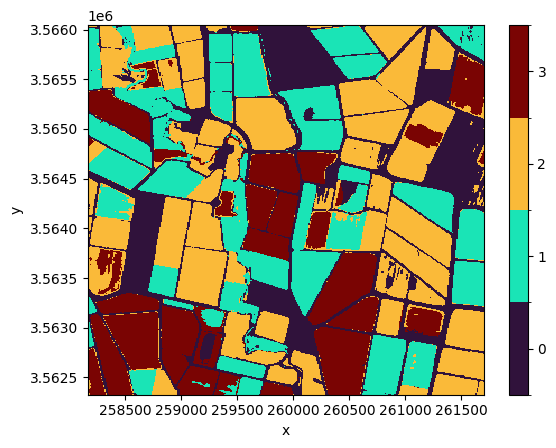

In [67]:
classified.plot(cmap = 'turbo',levels =  np.arange(-0.5, 4, 1),
                cbar_kwargs = {'ticks': range(4)})

In [68]:
import pandas as pd

In [74]:
ndvi_stack.shape

(131688, 12)

In [75]:
df = pd.DataFrame({'date': ndvi_stack.time.values})

for i in np.unique(classified.values):
  ndvi_mean = ndvi_stack[valid][labels == i].mean(axis = 0)
  df[f'cluster_{i}'] = ndvi_mean

In [76]:
df

,date,cluster_0,cluster_1,cluster_2,cluster_3
0,2025-01-31,0.306492,0.714478,0.565173,0.645241
1,2025-02-28,0.308772,0.807226,0.760738,0.734244
2,2025-03-31,0.322157,0.754695,0.763637,0.775731
3,2025-04-30,0.351315,0.530591,0.541132,0.786742
4,2025-05-31,0.366959,0.252549,0.248741,0.671242
5,2025-06-30,0.295959,0.149524,0.122609,0.445681
6,2025-07-31,0.192542,0.275094,0.113966,0.218078
7,2025-08-31,0.168944,0.497607,0.106273,0.131920
8,2025-09-30,0.201889,0.676646,0.103863,0.138728
9,2025-10-31,0.231300,0.572680,0.152180,0.192383


In [77]:
import matplotlib.pyplot as plt

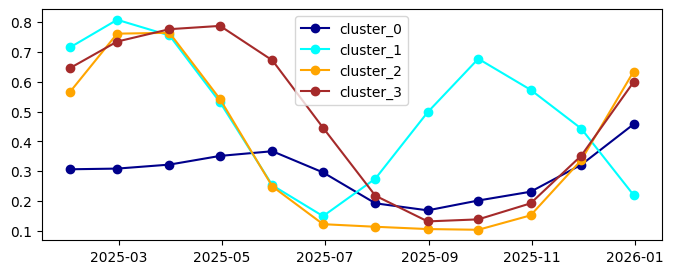

In [86]:
fig, ax = plt.subplots(figsize = (8, 3))

ax.plot(df.date, df.cluster_0, marker = 'o', label = 'cluster_0', color = 'darkblue')
ax.plot(df.date, df.cluster_1, marker ='o', color = 'cyan', label = 'cluster_1')
ax.plot(df.date, df.cluster_2, marker ='o', color = 'orange', label = 'cluster_2')
ax.plot(df.date, df.cluster_3, marker = 'o', color = 'brown', label = 'cluster_3')

ax.legend()